# **Step 1 : Data Preperation and exploration**


### **Setup**

In [1]:
import re #re works with patterns in text
from pathlib import Path # To make working with file/folder path easier
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats #statistical tests and calculations
from sklearn.decomposition import PCA #Principal Component Analysis
from sklearn.preprocessing import StandardScaler #Puts our numerical features onto a comporable scale
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 0
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})

SEX_COLOR = {"F": "#BBA1D9", "M": "#2F6F8F"}       # the same two colours are used for sex in every figure
ANCESTRIES = ["AFR", "ASN", "EUR"]                 # the three ancestries that have usable skull data

#Data location
Cranial_XLSX = Path("/content/ALL_Cranial ILD data.xlsx")
FACIAL_XLSX = Path("/content/ALL_Facial ILD data.xlsx")
TD_XLSX = Path("/content/ALL_Tissue Depth data.xlsx")


### **Take a sneak peek at the row files**
**Why?** : We can never clean data we haven't looked at.

In [2]:
for path in [Cranial_XLSX, FACIAL_XLSX, TD_XLSX]: # looping through the 3 files
  xl = pd.ExcelFile(path) # Opening the excel workbook and gather info about it
  print(f"\n{path.name}")
  for sheet in xl.sheet_names:
    shape = xl.parse(sheet, header=None).shape # Read the sheet as if everything is data
    print(f" {sheet:22s} {shape[0]:>4} rows x {shape[1]:>3} cols")


ALL_Cranial ILD data.xlsx
 Ref                       1 rows x   1 cols
 AFRF                     57 rows x  21 cols
 AFRM                     46 rows x  23 cols
 ASNF                     47 rows x  22 cols
 ASNM                     48 rows x  21 cols
 EURF                     47 rows x  25 cols
 EURM                     48 rows x  25 cols

ALL_Facial ILD data.xlsx
 Notes_Ref                 4 rows x   1 cols
 afrf_k                   67 rows x  51 cols
 afrf_r                   67 rows x  51 cols
 afrm_k                   67 rows x  49 cols
 afrm_r                   67 rows x  49 cols
 asnf_k                   67 rows x  49 cols
 asnf_r                   67 rows x  49 cols
 asnm_k                   67 rows x  48 cols
 asnm_r                   67 rows x  48 cols
 eurf_k                   67 rows x  50 cols
 eurf_r                   67 rows x  50 cols
 eurm_k                   67 rows x  49 cols
 eurm_r                   67 rows x  49 cols
 hisf_k                   67 rows x  50 cols
 h

In [3]:
print("Cranial_Cols, sheet 'AFRF' (African Females) :")
display(pd.read_excel(Cranial_XLSX, sheet_name="AFRF").iloc[:4, :10])
print("Facial, sheet 'afrf_k:")
display(pd.read_excel(FACIAL_XLSX, sheet_name="afrf_k").iloc[:4, :10])
print("Tissue Depth, sheet 'TD Reface':")
display(pd.read_excel(TD_XLSX, sheet_name="TD ReFace").iloc[-5:, :6])

print("\nCitations written inside the files:")
for path, sheet in [(Cranial_XLSX, "Ref"), (FACIAL_XLSX, "Notes_Ref")]:
    for text in pd.read_excel(path, sheet_name=sheet, header=None).stack().dropna():
        print(" -", text)

Cranial_Cols, sheet 'AFRF' (African Females) :


,Unnamed: 0,Unnamed: 1,Unnamed: 2,Sex,AUB,BBH,BNL,BPL,FRC,GOL
0,AFR001,AFR001,AFR001,F,116.16,136.13,105.35,105.89,122.61,193.77
1,AFR002,AFR002,AFR002,F,122.79,135.19,103.60,99.86,116.53,183.74
2,AFR003,AFR003,AFR003,F,122.59,126.35,96.13,87.09,105.02,177.72
3,AFR004,AFR004,AFR004,F,110.56,128.38,93.43,93.00,112.17,180.76


Facial, sheet 'afrf_k:


,Unnamed: 0,afr001,afr002,afr003,afr004,afr005,afr007,afr009,afr010,afr011
0,se-exL,49.074,53.376,51.100,53.298,51.346,50.719,54.203,50.424,49.912
1,se-exR,52.060,52.118,48.479,48.516,52.320,48.938,55.420,51.977,52.413
2,se-prn,41.981,40.327,40.396,44.794,43.807,43.100,43.284,37.583,44.399
3,se-acL,47.845,45.658,45.967,49.457,46.665,46.760,48.211,46.821,45.330


Tissue Depth, sheet 'TD Reface':


,ReFace ID,Sex,g,gn,li,ls
392,Median,NaN,5.470000,7.830000,15.120000,12.420000
393,Mean (L&R),NaN,NaN,NaN,NaN,NaN
394,NaN,NaN,NaN,NaN,NaN,NaN
395,Average,NaN,5.544987,8.163963,15.308708,12.510026
396,Rounded up,NaN,5.600000,8.200000,15.400000,12.600000



Citations written inside the files:
 - Simmons-Ehrhardt T, Ehrhardt C, Monson K. Evaluation of the suitability of cranial measurements obtained from surface-rendered CT scans of living people for estimating sex and ancestry. J Forensic Radiol Imag 2019;19:100338. doi:10.1016/j.jofri.2019.100338
 - Simmons-Ehrhardt TL, Flint T, Saunders CP, Monson KL (2020) Quantitative accuracy and 3D biometric matching of 388 statistically estimated facial approximations of live subjects. Forensic Img 21:200377. doi:10.1016/j.fri.2020.200377
 - Suffix "_k" designates measurements collected from CT-derived (k, known) models
 - Suffix "_r" designates measurements collected from ReFace approximations (r, ReFace) models


**Problems we just spotted:**

1. Facial sheets are **transposed**.
2. The tissue-depth sheet has **summary rows** (Mean, STD, ...) mixed with the people, plus empty "Unnamed" columns.
3. **IDs differ between files:** `CAU` (Cranial_Cols/tissue) vs `EUR`; ReFace sheets add an `R` prefix (`RAFR001`).
4. **12 Cranial_Cols rows have a different ID scheme** (`HWF52`, `HWM70`, ...) and sit inside the *African* sheets.
5. The Cranial_Cols sheets do **not all have the same layout** (extra ID columns, stray columns, and one sheet lacks the `OBBL` measurement).
6. The first sheet of each workbook only contains notes or references.

### **Cleaning: one tidy table per file**
**Goal:** one row = one person, and an `id` column spelled the same way in every table.

In [4]:
#Make subject IDs comparable across files
def canon_id(x):
  s = str(x).strip().upper() #Upper-case
  s = re.sub("^R(?=(AFR|ASN|EUR|CAU|HIS))", "", s) #Drop the 'R' that ReFace adds
  return re.sub(r"^CAU", "EUR", s) # Change CAU->EUR to have the same name convention

In [5]:
#Cranial_Cols measurments we care about
Cranial_CODES = ["AUB","BBH","BNL","BPL","FRC","GOL","MAB","NLB","NLHL",
                 "OBBL","OBHL","OCC","PAC","UFHT","WFB","XCB","ZYB"]
ID_PATTERN = r"^(AFR|ASN|EUR|CAU|HIS|HW)" # what a subject ID looks

#One tidy table of skull measurments (mm)
def load_Cranial(path) :
  xl = pd.ExcelFile(path)
  frames = []
  for sheet in xl.sheet_names: #skipping the first sheet since it's a citation
    raw = xl.parse(sheet, header=None)
    hdr_rows = [i for i in range(min(10, len(raw))) if raw.iloc[i].astype(str).str.strip().eq('Sex').any()]
    if not hdr_rows:
      continue
    h = hdr_rows[0]
    #Take the header row and clean it (if there's no name we give it "blank_n" as a name for now)
    names = [str(v).strip() if pd.notna(v) else f"blank_{j}" for j, v in enumerate(raw.iloc[h])]
    body = raw.iloc[h + 1:].reset_index(drop=True)
    body.columns = names
    id_col = None
    for j in range(names.index("Sex")) :
      vals = body.iloc[:, j].dropna().astype(str).str.strip()
      if len(vals) and vals.str.match(ID_PATTERN, case=False).mean() > 0.8:
        id_col, id_pos = names[j], j
        break
    if id_col is None :
      continue
    is_person = body[id_col].astype(str).str.strip().str.match(ID_PATTERN, case=False)
    part = pd.DataFrame({"id_raw": body.loc[is_person, id_col].astype(str).str.strip(),
                         "sex" : body.loc[is_person, "Sex"].astype(str).str.strip().str.upper()})
    for c in Cranial_CODES:
      part[c] = pd.to_numeric(body.loc[is_person, c], errors="coerce") if c in body.columns else np.nan
    part["sheet"] = sheet
    frames.append(part)
  out = pd.concat(frames, ignore_index=True)

  # 12 rows are labelled Hispanic but sit inside the African sheets.
  out["hw_flag"] = out["id_raw"].str.upper().str.match(r"^HW")
  def to_id(s):
    s = s.upper()
    return "HIS%03d" % int(re.findall(r"\d+", s)[0]) if s.startswith("HW") else canon_id(s) # HWF52 -> HIS052
  out["id"] = out["id_raw"].map(to_id)
  return out.rename(columns={c: "c_" + c for c in Cranial_CODES})

In [6]:
#Tidy table of facial distances (mm)
def load_facial(path, kind):
  xl = pd.ExcelFile(path)
  frames = []
  for sheet in xl.sheet_names[1:]:
    if not re.fullmatch(rf"[a-z]{{3}}[fm]_{kind}", sheet):
      continue
    #Reading the current Excel sheet into a pandas DataFrame and removing completly empty rows and cols
    raw = xl.parse(sheet, index_col=0).dropna(how="all").dropna(how="all", axis=1)
    raw.columns = [str(c).strip() for c in raw.columns]
    tidy = raw.T #Transposing to get 1 row = 1 person
    tidy.index.name = "id_raw" #We give index a name
    tidy = tidy.reset_index() #Turning index to normal col
    tidy["group"] = sheet.split("_")[0]
    frames.append(tidy)

  out = pd.concat(frames, ignore_index=True) #Combine teh sheets
  out["id"] = out["id_raw"].map(canon_id) #Standeraize the ID
  out = out.drop(columns='id_raw') #Drop the old messy ID
  dist_cols = [c for c in out.columns if c not in ("id", "group")]
  return out.rename(columns={c: f"{kind}_" + c.replace("-","_") for c in dist_cols})

In [7]:
#Tidy table of tissue depths (mm)
def load_td(path):
  df = pd.read_excel(path, sheet_name="TD ReFace")
  df.columns = [str(c).strip() for c in df.columns]
  n_before = len(df)
  df = df[df["ReFace ID"].astype(str).str.match(r"^(AFR|ASN|CAU|HIS)\d+")] #Removing summary Rows
  df = df.loc[:, ~df.columns.str.startswith("Unnamed")] #Removing empty cols
  df["id"] = df["ReFace ID"].map(canon_id)
  value_cols = [c for c in df.columns if c not in ("ReFace ID", "Sex", "id")]
  df[value_cols] = df[value_cols].apply(pd.to_numeric, errors="coerce") #Ensure the tissue-depth measurements are numeric
  df = df.drop(columns="ReFace ID").rename(columns={"Sex": "sex_td"})
  print(f"Tissue-depth sheet: {n_before - len(df)} non-person rows removed, {len(df)} people kept")
  return df.rename(columns={c: "td_" + c.replace(" ", "_") for c in value_cols})

In [8]:
#Runing the functions
cranial = load_Cranial(Cranial_XLSX)
face_k = load_facial(FACIAL_XLSX, "k")
face_r = load_facial(FACIAL_XLSX, "r")
td = load_td(TD_XLSX)

Tissue-depth sheet: 10 non-person rows removed, 387 people kept


In [9]:
for name, d in [("cranial", cranial), ("face_k (real)", face_k), ("face_r (ReFace)", face_r), ("tissue depth", td)]:
    print(f"{name:16s} {d.shape[0]:>4} people x {d.shape[1]:>3} columns   duplicate ids: {d.id.duplicated().sum()}")

cranial           287 people x  22 columns   duplicate ids: 0
face_k (real)     388 people x  68 columns   duplicate ids: 0
face_r (ReFace)   388 people x  68 columns   duplicate ids: 0
tissue depth      387 people x  42 columns   duplicate ids: 0


### **Merge and Validate**

**Merge = inner join on `id`:** we keep only people present in **all three** files, because the model needs skull (input) and face (target) together. The price of an inner join is paid in people, so we measure it below.

**Validate:** a join can be silently wrong. We test it with facts that must agree across files: the **sex** of each person is stored in three places, and the **ancestry** in two.

In [10]:
#Taking all the cols that starts with c_ (17 Skull measurment)
Cranial_Cols = [c for c in cranial.columns if c.startswith("c_")]
#Taking all the cols that start with k_ (66 Real CT facial measurements)
K_Cols = [c for c in face_k.columns if c.startswith("k_")]
#Takin all the cols that start with r_ (66 ReFace measurements)
R_Cols  = [c for c in face_r.columns if c.startswith("r_")]
#Taking all the cols that start with td_ (40 Tissue depth measurements)
TD_Cols = [c for c in td.columns if c.startswith("td_")]

In [11]:
#Merging
data = (cranial.rename(columns={"sheet": "cranial_sheet"})
        .merge(face_k.rename(columns={"group": "face_group"}), on="id")
        .merge(face_r.drop(columns="group"), on="id")
        .merge(td, on="id"))
assert data.id.is_unique #check if id are unique else assert will stop the prog and gives an error
data["ancestry"] = data.id.str[:3] #Take the first 3 letter of the ID to say the origin of the subject
data["sex_face"] = data.face_group.str[-1].str.upper()    #extract the last letter of the ID which indicate the sex of the subject
print("People in all three files:", len(data))
print("Columns:", data.shape[1], f"({len(Cranial_Cols)} skull, {len(K_Cols)} real CT face, {len(R_Cols)} ReFace, {len(TD_Cols)} tissue depth)")

People in all three files: 282
Columns: 198 (17 skull, 66 real CT face, 66 ReFace, 40 tissue depth)


In [12]:
#Validation
sex_ok_face = data.sex == data.sex_face
sex_ok_td = data.sex == data.sex_td
ancestry_ok = data.ancestry == data.face_group.str[:3].str.upper()
print(f"Sex agrees (cranial vs facial):       {sex_ok_face.mean():.1%}")
print(f"Sex agrees (cranial vs tissue depth): {sex_ok_td.mean():.1%}")
print(f"Ancestry agrees (ID prefix vs facial sheet): {ancestry_ok.mean():.1%}")
print("Rows where cranial and facial files disagree on sex:", data.loc[~sex_ok_face, "id"].tolist())

Sex agrees (cranial vs facial):       99.3%
Sex agrees (cranial vs tissue depth): 99.3%
Ancestry agrees (ID prefix vs facial sheet): 100.0%
Rows where cranial and facial files disagree on sex: ['HIS052', 'HIS069']


In [13]:
hw = data[data.hw_flag][["id_raw", "id", "cranial_sheet", "sex", "sex_face"]].copy()
hw["sex_agrees"] = hw.sex == hw.sex_face
display(hw.reset_index(drop=True))

regular = data[~data.hw_flag]
print(f"Sheets these 12 rows were found in: {hw.cranial_sheet.value_counts().to_dict()}  (African sheets, but their ID says Hispanic)")
print(f"Sex agreement for the {len(regular)} regular rows: {(regular.sex == regular.sex_face).mean():.1%}")
print(f"Sex agreement for the {len(hw)} HW rows:      {hw.sex_agrees.mean():.1%} ({int(hw.sex_agrees.sum())} of {len(hw)})")

,id_raw,id,cranial_sheet,sex,sex_face,sex_agrees
0,HWF100,HIS100,AFRF,F,F,True
1,HWF52,HIS052,AFRF,F,M,False
2,HWF69,HIS069,AFRF,F,M,False
3,HWF77,HIS077,AFRF,F,F,True
4,HWF78,HIS078,AFRF,F,F,True
5,HWF89,HIS089,AFRF,F,F,True
6,HWF95,HIS095,AFRF,F,F,True
7,HWF96,HIS096,AFRF,F,F,True
8,HWF98,HIS098,AFRF,F,F,True
9,HWF99,HIS099,AFRF,F,F,True


Sheets these 12 rows were found in: {'AFRF': 10, 'AFRM': 2}  (African sheets, but their ID says Hispanic)
Sex agreement for the 270 regular rows: 100.0%
Sex agreement for the 12 HW rows:      83.3% (10 of 12)


**Decision:**

**Exclude the 12 `HW` rows from modelling (they stay in the table, flagged).**

For three reasons:

 1. sex agrees for **100%** of the regular rows but only **10 of 12** HW rows, so the number-based link is wrong for at least two people and we cannot tell which others are wrong.

  2.  Their ancestry is ambiguous.
   
  3.  A wrong link silently feeds a wrong face to the model, while the cost of dropping them is only 12 of 282 people (4%).
  
Note that the IDs *do* exist in the facial and tissue-depth files, so this is a doubt about the **link**, not about missing data.



In [14]:
data["use_for_training"] = ~data.hw_flag #We don't want the HW
trusted = data[data.use_for_training].copy()      # the 270 people used in the analysis below

assert set(trusted.ancestry) == set(ANCESTRIES), "trusted should contain exactly AFR, ASN, EUR"
print("Trusted people:", len(trusted))
print(pd.crosstab(trusted.ancestry, trusted.sex, margins=True))

Trusted people: 270
sex         F    M  All
ancestry               
AFR        46   41   87
ASN        44   47   91
EUR        45   47   92
All       135  135  270


### Who is lost in the join?
An inner join drops anyone missing from one of the files. We measure it

In [15]:
rows = []
for name, table in [("cranial", cranial), ("facial", face_k), ("tissue depth", td)]:
    lost = table[~table.id.isin(data.id)]
    rows.append((name, len(table), len(table) - len(lost), len(lost), int(lost.id.str.startswith("HIS").sum())))
loss = pd.DataFrame(rows, columns=["file", "people in file", "kept in merged table", "lost", "of which Hispanic (HIS)"])
display(loss)
print("Cranial people lost:", cranial[~cranial.id.isin(data.id)].id.tolist())

,file,people in file,kept in merged table,lost,of which Hispanic (HIS)
0,cranial,287,282,5,0
1,facial,388,282,106,86
2,tissue depth,387,282,105,88


Cranial people lost: ['AFR101', 'AFR108', 'ASN012', 'ASN095', 'EUR096']


Almost all lost people are the **Hispanic** group, who have faces and tissue depths but (almost) no skull data. So the model can only cover **African, Asian and European** people. The 20 non-Hispanic facial people and the 5 cranial people lost have no counterpart in another file.


### Which people are used in which analysis?
Different questions need different people. We state it once here, so no number is ambiguous later.

In [16]:
populations = pd.DataFrame([
    ("Skull measurements, Skull vs face", len(trusted), "trusted people (need skull + face)"),
    ("Facial distances", len(face_k), "all facial people, Hispanic included"),
    ("Real face vs ReFace", len(face_k), "all 388, and also the 270 trusted people"),
    ("Tissue depths", len(td), "all tissue-depth people, Hispanic included"),
], columns=["section", "people", "who"])
display(populations)

,section,people,who
0,"Skull measurements, Skull vs face",270,trusted people (need skull + face)
1,Facial distances,388,"all facial people, Hispanic included"
2,Real face vs ReFace,388,"all 388, and also the 270 trusted people"
3,Tissue depths,387,"all tissue-depth people, Hispanic included"


In [17]:
# Missing values (after the merge)
missing = data[Cranial_Cols + K_Cols + TD_Cols].isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Columns with missing values:")
print(missing.to_string())
print("\nWho is missing c_OBBL?", data[data.c_OBBL.isna()].groupby(["ancestry", "sex"]).size().to_dict())

Columns with missing values:
td_az_R     148
td_az_L     147
c_OBBL       47
td_m         16
td_sg         8
td_gn         6
td_me         5
td_v          4
td_g          3
td_op         3
td_pg         3
td_im2_R      3
td_im2_L      3
td_mmb_L      3
td_mmb_R      3
td_n          3
td_go_L       2
td_mr_L       2
td_mp         2
td_sm2_R      2
td_go_R       2
td_mr_R       2
td_sm2_L      2
td_ls         1
td_li         1
td_mls        1
td_sn         1

Who is missing c_OBBL? {('ASN', 'M'): 47}


**Missing data is structured, not random.**

`c_OBBL` (orbital breadth) is missing for **every Asian male** (47 people), so filling it with an average would invent data: so we **do not use this column** as an input.

The tissue-depth columns `az_L/az_R` are 38% empty

### **EDA : *E***xploratory ***D***ata ***A***nalysis

EDA is done on **all 270 trusted people**, and **no model is fitted for the purpose of choosing features**.

There is therefore no train/test split yet, and the table is called `trusted`, not "training set". In


1. *Who's in the dataset ?*

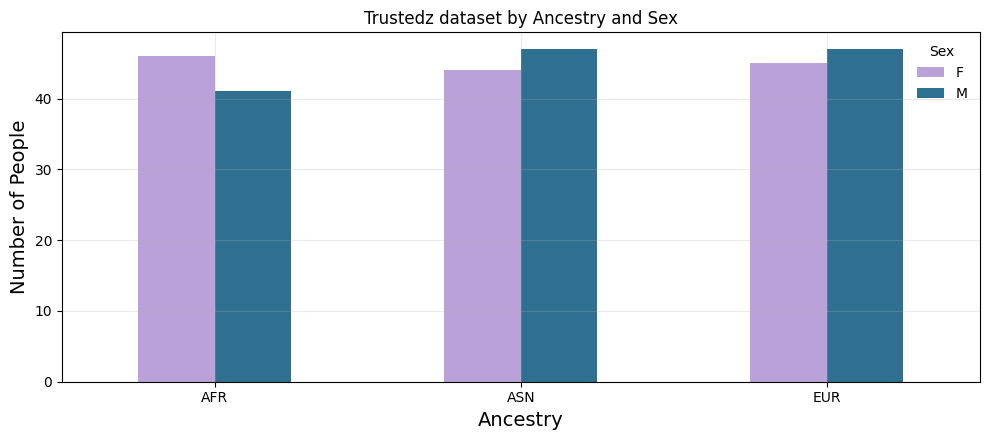

In [18]:
ct = pd.crosstab(trusted.ancestry, trusted.sex)
ax = ct.plot.bar(figsize=(10, 4.5), width = 0.50, color =[SEX_COLOR['F'], SEX_COLOR['M']], rot=0)
ax.set_xlabel("Ancestry", fontsize=14)
ax.set_ylabel("Number of People", fontsize=14)
ax.set_title("Trustedz dataset by Ancestry and Sex")
ax.legend(title="Sex", frameon=False)
plt.tight_layout()
plt.show()

**Takeaway:**

A well balanced sample (41 to 47 per sex per group) of **three** ancestries:
* African (AFR)
* Asian (ASN)
* European (EUR)

There is no usable Hispanic skull data, so our model cannot claim to cover Hispanic people, and no group from North Africa or the Middle East is present.

2.  *The skull measurements :*

    *How big are the numbers? Are there errors? How do they differ by sex and ancestry? Which move together?*

In [19]:
Skull_Cols = [c for c in Cranial_Cols if c != "c_OBBL"]
display(trusted[Skull_Cols].describe().T[["count", "mean", "std", "min", "max"]].round(1))


,count,mean,std,min,max
c_AUB,270.0,121.9,5.9,107.7,140.2
c_BBH,270.0,139.5,5.9,122.2,153.3
c_BNL,270.0,103.6,5.5,92.2,119.7
c_BPL,270.0,97.8,6.7,83.5,116.7
c_FRC,270.0,113.6,5.1,101.8,126.1
c_GOL,270.0,185.5,8.4,163.9,205.9
c_MAB,270.0,64.1,4.6,54.3,76.8
c_NLB,270.0,24.6,2.2,18.8,31.0
c_NLHL,270.0,52.2,3.0,45.2,62.9
c_OBHL,270.0,34.0,2.0,28.2,40.3


In [20]:
#Data quality: outliers and distribution shape
by_cell = trusted.groupby(["ancestry", "sex"])[Skull_Cols]
z = (trusted[Skull_Cols] - by_cell.transform("mean")) / by_cell.transform("std")      # z-score inside each ancestry x sex cell
n_values = z.size
print(f"Values more than 3 SD from their own group mean: {int((z.abs() > 3).sum().sum())} of {n_values}")
print(f"Values more than 3.5 SD from their own group mean: {int((z.abs() > 3.5).sum().sum())}")
print(f"Largest |skewness| over the 16 measurements: {trusted[Skull_Cols].skew().abs().max():.2f}")
shapiro_p = [stats.shapiro(trusted[c])[1] for c in Skull_Cols]
print(f"Measurements failing a normality test: {sum(p < 0.05 for p in shapiro_p)} of 16")

Values more than 3 SD from their own group mean: 5 of 4320
Values more than 3.5 SD from their own group mean: 0
Largest |skewness| over the 16 measurements: 0.45
Measurements failing a normality test: 4 of 16


**Takeaway:** No implausible values, skewness is small, and a handful of pooled "non-normal" results is expected because pooling three ancestries and two sexes mixes several bell curves. We therefore keep all values (no outlier removal) and use ANOVA, which is robust with about 90 people per group.

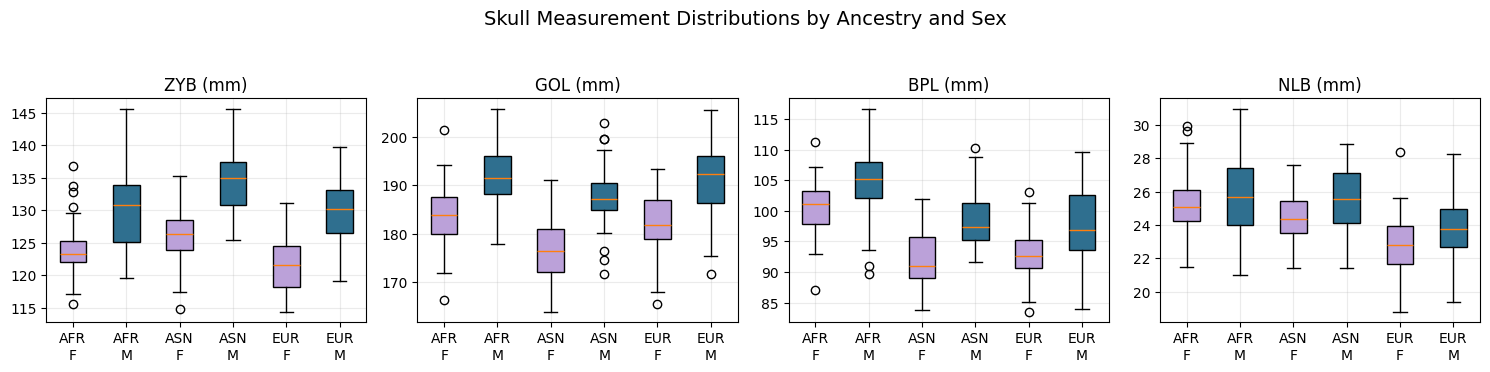

In [21]:
def grouped_box(ax, df, col):
  groups = [(a,s) for a in ANCESTRIES for s in ["F", "M"]]
  values = [df[(df.ancestry == a) & (df.sex == s)][col].dropna() for a, s in groups]
  bp = ax.boxplot(values, patch_artist=True)
  ax.set_xticklabels([f"{a}\n{s}" for a, s in groups], fontsize=10)
  for box, (a, s) in zip(bp["boxes"], groups):
    box.set_facecolor(SEX_COLOR[s])
  ax.set_title(col[2:] + " (mm)", fontsize=12)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, col in zip(axes, ["c_ZYB", "c_GOL", "c_BPL", "c_NLB"]):
  grouped_box(ax, trusted, col)
fig.suptitle(
    "Skull Measurement Distributions by Ancestry and Sex",
    fontsize=14,
    y=1.05
)
plt.tight_layout()
plt.show()

**Takeaway :**

The Cranial_Cols measurements have systematic variation across sex and ancestry.

In [22]:
#Cohen's d for two samples (a minus b).
def cohens_d(a, b):
    a, b = a.dropna(), b.dropna()
    pooled_var = ((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2)
    return (a.mean() - b.mean()) / np.sqrt(pooled_var)

#Male minus female d computed inside each group, then averaged
def sex_effect(df, col, sex_col="sex", by="ancestry"):
    return np.mean([cohens_d(g.loc[g[sex_col] == "M", col], g.loc[g[sex_col] == "F", col]) for _, g in df.groupby(by)])

#Bootstrap 95% confidence interval of sex_effect.
def sex_effect_ci(df, col, sex_col="sex", by="ancestry", n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    cells = [(g.loc[g[sex_col] == "M", col].dropna().to_numpy(), g.loc[g[sex_col] == "F", col].dropna().to_numpy())
             for _, g in df.groupby(by)]
    boot = []
    for _ in range(n_boot):
        ds = []
        for m, f in cells:
            mb, fb = rng.choice(m, len(m)), rng.choice(f, len(f))
            pooled = np.sqrt(((len(mb) - 1) * mb.var(ddof=1) + (len(fb) - 1) * fb.var(ddof=1)) / (len(mb) + len(fb) - 2))
            ds.append((mb.mean() - fb.mean()) / pooled)
        boot.append(np.mean(ds))
    return np.percentile(boot, [2.5, 97.5])

In [23]:
# Holm step-down correction for testing many hypotheses at once.
def holm(p):
    p = np.asarray(p)
    order = np.argsort(p) #smallest p first
    m = len(p)
    adjusted = np.empty(m)
    running = 0.0
    for rank, idx in enumerate(order):
        running = max(running, (m - rank) * p[idx])
        adjusted[idx] = min(1.0, running)
    return adjusted

#Format of p  : report very small p-values as < 0.001.
def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

In [24]:
rows = []
for c in Skull_Cols:
    d = sex_effect(trusted, c)
    lo, hi = sex_effect_ci(trusted, c)
    groups = [g[c].dropna() for _, g in trusted.groupby("ancestry")]
    F, p = stats.f_oneway(*groups)                       # one-way ANOVA across the 3 ancestries
    everyone = np.concatenate(groups)
    eta2 = sum(len(g) * (g.mean() - everyone.mean()) ** 2 for g in groups) / ((everyone - everyone.mean()) ** 2).sum()   # SS_between / SS_total
    rows.append((c[2:], d, lo, hi, F, p, eta2))
eff = pd.DataFrame(rows, columns=["measurement", "sex_d", "d_lo", "d_hi", "ancestry_F", "ancestry_p", "ancestry_eta2"]).set_index("measurement")
eff["ancestry_p_holm"] = holm(eff.ancestry_p)

In [25]:
#Bars ordered by STRENGTH |value|
def signed_barh(ax, values, title, lo=None, hi=None):
  order = values.abs().sort_values().index
  v = values[order]
  ax.barh(v.index, v.values, color=[SEX_COLOR["M"] if x >= 0 else SEX_COLOR["F"] for x in v.values])
  if lo is not None:
        ax.errorbar(v.values, range(len(v)), xerr=[v.values - lo[order].values, hi[order].values - v.values],
                    fmt="none", ecolor="black", capsize=2, lw=1)
  ax.axvline(0, color="black", lw=0.8)
  ax.set_title(title)

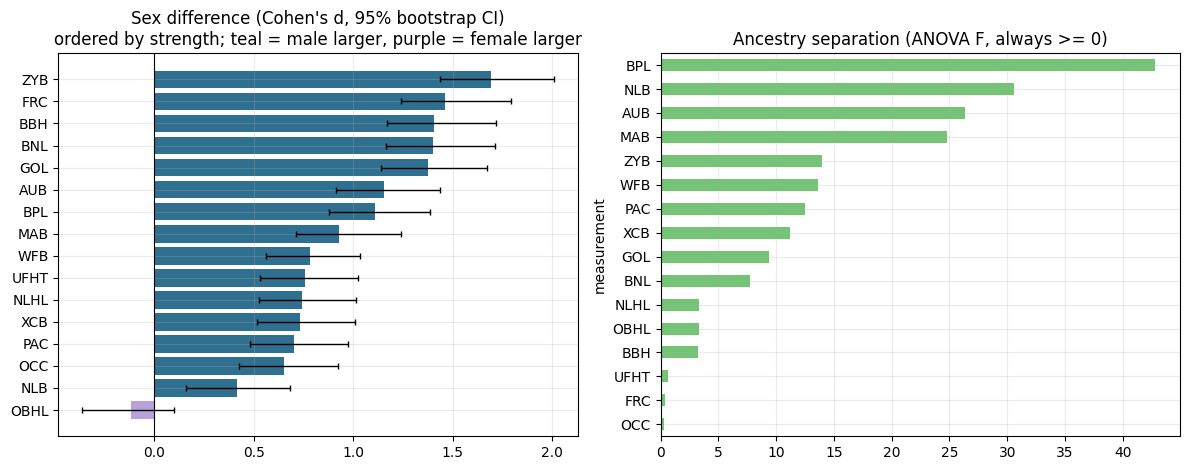

Measurements where the FEMALE mean is higher: {'OBHL': -0.12}
Sex differences whose 95% CI excludes 0: 15 of 16


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
signed_barh(axes[0], eff.sex_d, "Sex difference (Cohen's d, 95% bootstrap CI)\nordered by strength; teal = male larger, purple = female larger", eff.d_lo, eff.d_hi)
eff.ancestry_F.sort_values().plot.barh(ax=axes[1], color="#74c476")
axes[1].set_title("Ancestry separation (ANOVA F, always >= 0)")
plt.tight_layout(); plt.show()

print("Measurements where the FEMALE mean is higher:", {k: round(v, 2) for k, v in eff.sex_d[eff.sex_d < 0].items()})
print(f"Sex differences whose 95% CI excludes 0: {int(((eff.d_lo > 0) | (eff.d_hi < 0)).sum())} of {len(eff)}")

In [27]:
table = eff.sort_values("ancestry_F", ascending=False)[["ancestry_F", "ancestry_eta2", "ancestry_p", "ancestry_p_holm"]].copy()
table["ancestry_p"] = table.ancestry_p.map(fmt_p)
table["ancestry_p_holm"] = table.ancestry_p_holm.map(fmt_p)
table = table.round({"ancestry_F": 1, "ancestry_eta2": 3})
table.columns = ["F", "eta-squared", "p (raw)", "p (Holm-corrected)"]
display(table)

n_sig = int((eff.ancestry_p_holm < 0.05).sum())
not_sig = eff.index[eff.ancestry_p_holm >= 0.05].tolist()
print(f"{n_sig} of {len(eff)} measurements differ between ancestries after Holm correction (p < 0.05).")
print("Not significant after correction:", not_sig)

# Robustness: ANOVA ignores sex. Remove each sex's mean first, then test ancestry again.
sex_adjusted_p = []
for c in Skull_Cols:
    adjusted = trusted[c] - trusted.groupby("sex")[c].transform("mean")
    sex_adjusted_p.append(stats.f_oneway(*[adjusted[trusted.ancestry == a] for a in ANCESTRIES])[1])
print(f"After removing sex differences first: {int((holm(sex_adjusted_p) < 0.05).sum())} of 16 significant.")

,F,eta-squared,p (raw),p (Holm-corrected)
measurement,,,,
BPL,42.8,0.243,< 0.001,< 0.001
NLB,30.6,0.186,< 0.001,< 0.001
AUB,26.3,0.165,< 0.001,< 0.001
MAB,24.8,0.157,< 0.001,< 0.001
ZYB,13.9,0.094,< 0.001,< 0.001
WFB,13.6,0.092,< 0.001,< 0.001
PAC,12.5,0.086,< 0.001,< 0.001
XCB,11.2,0.077,< 0.001,< 0.001
GOL,9.4,0.066,< 0.001,< 0.001


10 of 16 measurements differ between ancestries after Holm correction (p < 0.05).
Not significant after correction: ['BBH', 'FRC', 'NLHL', 'OBHL', 'OCC', 'UFHT']
After removing sex differences first: 10 of 16 significant.


**Takeaway:**

##### ***1. Sex Differences:***

**15 of 16** measurements are larger in men with a 95% interval that excludes zero. The strongest are ZYB, FRC, BBH, BNL and GOL.

 **OBHL is the only one where women are (slightly) higher, and its d is about -0.12 with an interval that includes 0: no real difference.** All d values are between about -0.1 and 1.7, which is the plausible range for human skulls.


##### ***2. Ancestry Differences***

**10 of 16** measurements differ between ancestries after Holm correction.

BPL separates the ancestries best, then NLB, AUB and MAB.

**Six are not significant: UFHT, FRC, OCC, and also NLHL, OBHL and BBH** (whose raw p is near 0.04 but does not survive correction). Removing the sex effect first leaves the result unchanged.



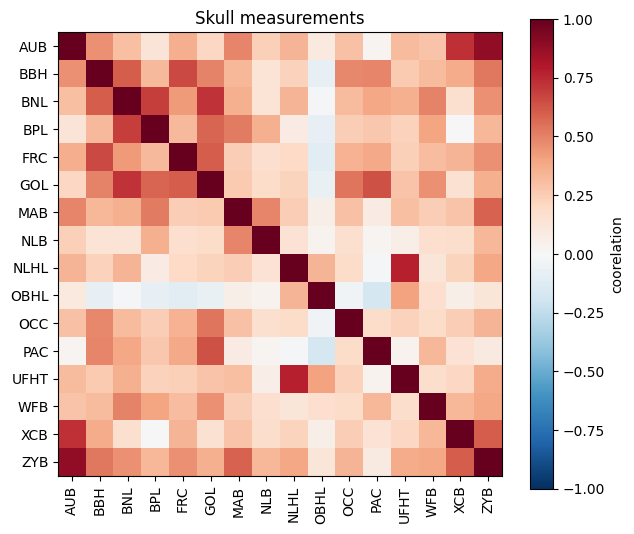

In [28]:
corr = trusted[Skull_Cols].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(Skull_Cols)))
ax.set_xticklabels([c[2:] for c in Skull_Cols], rotation=90)
ax.set_yticks(range(len(Skull_Cols)))
ax.set_yticklabels([c[2:] for c in Skull_Cols])
ax.grid(False)
fig.colorbar(im, label="coorelation")
ax.set_title("Skull measurements")
plt.tight_layout()
plt.show()

In [29]:
pairs = [(a[2:], b[2:], abs(corr.loc[a, b])) for i, a in enumerate(Skull_Cols) for b in Skull_Cols[i+1:]]
print("Most correlated pairs :")
print(pd.DataFrame(pairs, columns=["a", "b", "|r|"]).sort_values("|r|", ascending=False).head(4).round(2).to_string(index=False))

Most correlated pairs :
   a    b  |r|
 AUB  ZYB 0.89
NLHL UFHT 0.77
 AUB  XCB 0.73
 BNL  GOL 0.72


In [30]:
pca_skull = PCA().fit(StandardScaler().fit_transform(trusted[Skull_Cols]))        # standardise first: measurements have different scales
cum_skull = np.cumsum(pca_skull.explained_variance_ratio_)
print("\nVariance explained by each of the first 5 skull components:", pca_skull.explained_variance_ratio_[:5].round(2))
print(f"The first 5 components together explain {cum_skull[4]:.0%} of the variation of the 16 measurements.")


Variance explained by each of the first 5 skull components: [0.36 0.14 0.1  0.09 0.06]
The first 5 components together explain 75% of the variation of the 16 measurements.


**Takeaway** : Some measurements are close to duplicates (the strongest pair is AUB-ZYB), so they carry **overlapping information**.

The first 5 principal components explain **75%** of the skull variation (36% + 14% + 10% + 9% + 6%): the 16 measurements are *not* 16 independent pieces of information.

3.  *The facial distances :*
  
    Here we use **all 388 people of the facial file**, Hispanic included, because this section does not involve skulls

In [31]:
#Organizing the facial data
fk = face_k.copy()
fk["ancestry"] = fk.group.str[:3].str.upper()
fk["sex"] = fk.group.str[-1].str.upper()

In [32]:
#id the facial landmarks
Landmarks = sorted({p for c in K_Cols for p in c[2:].split("_")})
#Extracts the unique landmark names from the facial distance column names
print(f"{len(fk)} people; {len(K_Cols)} distances = all pairs of {len(Landmarks)} landmarks:")
print(Landmarks)

388 people; 66 distances = all pairs of 12 landmarks:
['acL', 'acR', 'chL', 'chR', 'exL', 'exR', 'li', 'ls', 'prn', 'se', 'sn', 'sto']


Shortest distances :


,mean_mm,sd_mm,cv_%
ls_sto,7.8,2.1,26.5
li_sto,10.3,2.3,21.9
sn_ls,16.6,2.6,15.7



Longest distances :


,mean_mm,sd_mm,cv_%
exL_exR,97.0,6.1,6.3
exL_chR,100.2,5.3,5.3
exR_chL,100.3,6.7,6.6


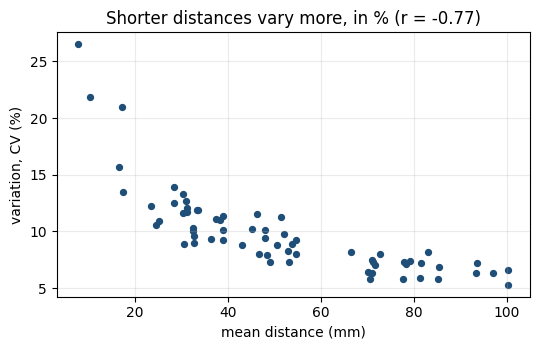

In [33]:
#Summarizing the facial distances
K = fk[K_Cols]
desc = pd.DataFrame({
    "mean_mm" : K.mean(), #Avg distance
    "sd_mm" : K.std(),   #How much the distance vary btw people
    "cv_%" : 100*K.std() / K.mean() #StD as a percentage of the mean
}).round(1)
desc.index = [i[2:] for i in desc.index]
print("Shortest distances :")
display(desc.sort_values("mean_mm").head(3))
print("\nLongest distances :")
display(desc.sort_values("mean_mm").tail(3))

#"Short distances vary more (in %)
r_cv = np.corrcoef(desc.mean_mm, desc["cv_%"])[0, 1]
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.scatter(desc.mean_mm, desc["cv_%"], s=18, color="#1f4e79")
ax.set_xlabel("mean distance (mm)"); ax.set_ylabel("variation, CV (%)")
ax.set_title(f"Shorter distances vary more, in % (r = {r_cv:.2f})")
plt.tight_layout(); plt.show()

**Takeaway:**

The data hold **388 people, 12 landmarks, 66 distances** in millimetres. Short distances (lips, mouth opening) vary much more in percent than long ones.

Part of this is real variation, but part is probably **measurement error**: a 0.5 mm placement error is 6% of an 8 mm distance and 0.5% of a 100 mm one.

The files do not report the landmark placement error: **we do not know the noise floor of our ground truth**.

PCA on the LOG of the distances:
*Why log?*

Differences in face size are multiplicative (a bigger face scales all distances by a similar percentage); the log turns that into an addition, and stops the 100 mm distances from dominating the 8 mm ones.

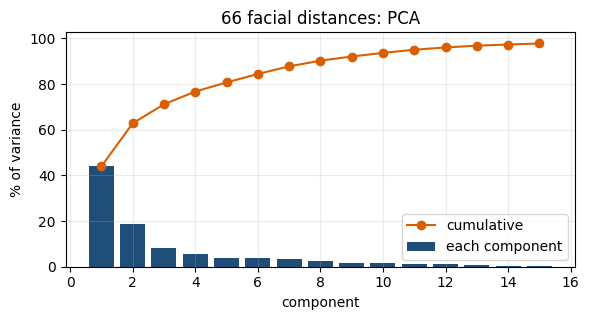

PC1 explains 44%; 5 components explain 81%; 8 components explain 90%
|Correlation| of PC1 with overall face size: 0.988


In [34]:
log_k = np.log(K)
pca_face = PCA().fit(log_k)
cum_face = np.cumsum(pca_face.explained_variance_ratio_)
size = log_k.mean(axis=1)                              # mean log-distance = log of the 'geometric mean size' of the face
pc1 = pca_face.transform(log_k)[:, 0]

fig, ax = plt.subplots(figsize=(6, 3.3))
ax.bar(range(1, 16), pca_face.explained_variance_ratio_[:15] * 100, color="#1f4e79", label="each component")
ax.plot(range(1, 16), cum_face[:15] * 100, "o-", color="#d95f02", label="cumulative")
ax.set_xlabel("component"); ax.set_ylabel("% of variance"); ax.legend()
ax.set_title("66 facial distances: PCA")
plt.tight_layout(); plt.show()
print(f"PC1 explains {cum_face[0]:.0%}; 5 components explain {cum_face[4]:.0%}; 8 components explain {cum_face[7]:.0%}")
print(f"|Correlation| of PC1 with overall face size: {abs(np.corrcoef(pc1, size)[0, 1]):.3f}")

**Takeaway:**

The first component explains **44%** of the variation and is simply **overall face size** (|r| = 0.988 with the geometric-mean size). Five components explain 81% and eight explain 90%. So a model can predict a handful of numbers instead of 66, which is more stable with only 270 people

In [35]:
grp = fk.ancestry + fk.sex
r2 = {}
for c in K_Cols :
  y = fk[c]
  sst = ((y - y.mean())**2).sum() #Total variation in the facial distance across indiv
  sse = ((y- y.groupby(grp).transform("mean"))**2).sum() #Variation remaining within the ancestry and sex grps.
  r2[c[2:]] = 1 - sse / sst #The propotion of variation explaind by diff btw grp means

r2 = pd.Series(r2)
print(f"Share of variance explained by grp means: median {r2.median():.0%}, best {r2.max():.0%} ({r2.idxmax()}), worst {r2.min():.0%} ({r2.idxmin()})")

size_df = pd.DataFrame({"size_mm": np.exp(size), "ancestry": fk.loc[size.index, "ancestry"], "sex": fk.loc[size.index, "sex"]})
display(size_df.groupby(["ancestry", "sex"]).size_mm.mean().unstack().round(1))


Share of variance explained by grp means: median 41%, best 63% (acR_ls), worst 21% (exL_acL)


sex,F,M
ancestry,,
AFR,46.0,48.9
ASN,42.9,45.4
EUR,42.2,46.5
HIS,42.1,46.0


**Takeaway**

Knowing only a person's sex and ancestry explains a **median of 41%** of each facial distance, and men have larger faces than women in every ancestry group. So any skull-based model must be compared with **"guess the group average"**, not with "guess the overall average".

4.  *Real face vs ReFace estimate :*

How close are the ReFace estimates to real measurements?

all people in the facial file      n=388 | mean abs error 2.27 mm | mean bias -0.79 mm | median correlation 0.76
the 270 trusted people (our people) n=270 | mean abs error 2.20 mm | mean bias -0.82 mm | median correlation 0.77


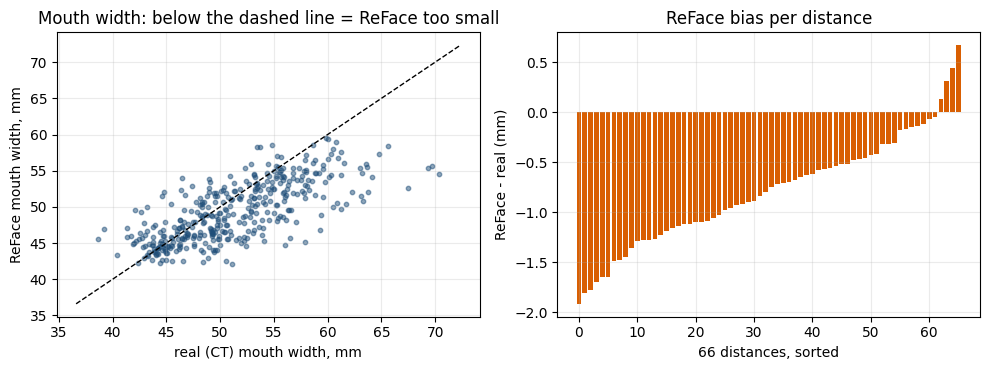

In [36]:
real = fk.set_index("id")[K_Cols].copy()
reface = face_r.set_index("id")[R_Cols].copy()
reface.columns = K_Cols                                  # same column names, so the two tables line up
common = real.index.intersection(reface.index)
real, reface = real.loc[common], reface.loc[common]

def reface_report(ids, label):
    diff = reface.loc[ids] - real.loc[ids]               # negative = ReFace distance too small
    bias = diff.mean()                                   # average signed error per distance
    corr_r = real.loc[ids].corrwith(reface.loc[ids])     # does ReFace follow differences BETWEEN people?
    print(f"{label:34s} n={len(ids):>3} | mean abs error {diff.abs().to_numpy().mean():.2f} mm | mean bias {bias.mean():+.2f} mm | median correlation {corr_r.median():.2f}")
    return bias

bias = reface_report(common, "all people in the facial file")
reface_report(trusted.id[trusted.id.isin(common)], "the 270 trusted people (our people)")

j = "k_chL_chR"                                          # mouth width: the distance with the largest bias
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(real[j], reface[j], s=10, alpha=0.5, color="#1f4e79")
lims = [min(real[j].min(), reface[j].min()) - 2, max(real[j].max(), reface[j].max()) + 2]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set_xlabel("real (CT) mouth width, mm"); axes[0].set_ylabel("ReFace mouth width, mm")
axes[0].set_title("Mouth width: below the dashed line = ReFace too small")
axes[1].bar(range(len(bias)), bias.sort_values().to_numpy(), color="#d95f02")
axes[1].set_xlabel("66 distances, sorted"); axes[1].set_ylabel("ReFace - real (mm)")
axes[1].set_title("ReFace bias per distance")
plt.tight_layout(); plt.show()

**Takeaway:**

ReFace follows individual differences reasonably well (median correlation 0.76) but is **systematically too small** (-0.79 mm on average, up to about -1.9 mm for mouth width). Its mean absolute error is **2.27 mm on all 388 people and 2.20 mm on our 270 trusted people**. *When we compare our model with ReFace in Step 2 we must use the same people*, so 2.20 mm is the number to beat.

5.  *Tissue Depths :*

In [37]:
# Landmark names, read from the file's own reference sheet
ref = pd.read_excel(TD_XLSX, sheet_name="Landmarks_Ref", header=None)
reference = {}
for code_col, name_col in [(0, 1), (3, 4)]:
    for code_, name in zip(ref[code_col], ref[name_col]):
        if isinstance(code_, str) and re.match(r"^[A-Za-z0-9]+['\-]", code_):  # rows like "g-g'" or "mmb'mmb'"
            reference[re.match(r"[A-Za-z0-9]+", code_).group(0).lower()] = name

TD_Base = sorted({c[3:].removesuffix("_L").removesuffix("_R") for c in TD_Cols})
dictionary = pd.DataFrame({"column": TD_Base, "meaning (from the file)": [reference.get(b, "NOT DEFINED in the reference sheet") for b in TD_Base]})
display(dictionary.T)
print("Columns with no definition in the file:", dictionary.loc[dictionary["meaning (from the file)"].str.startswith("NOT"), "column"].tolist())

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27
column,acp,az,g,gn,go,ic,im2,li,ls,m,me,mio,mls,mmb,mn,mp,mr,mso,n,op,pg,rhi,sc,sg,sm2,sn,v,zy
meaning (from the file),Alare curvature point,NOT DEFINED in the reference sheet,Glabella,Gnathion,Gonion,Infra canine,Infra M2,Labrale inferius,Labrale superius,Menton,NOT DEFINED in the reference sheet,Mid-infraorbital,Mentolabial sulcus,Mid-mandibular border,Mid-nasal,Mid-philtrum,Mid-ramus,Mid-supraorbital,Nasion,Opisthocranion,Pogonion,Rhinion,Supra canine,NOT DEFINED in the reference sheet,Supra M2,Subnasale,Vertex,Zygion


Columns with no definition in the file: ['az', 'me', 'sg']


In [38]:
T = td[TD_Cols]
td_desc = pd.DataFrame({"mean_mm": T.mean(), "sd_mm": T.std(), "missing_%": 100 * T.isna().mean()}).round(1)
td_desc.index = [i[3:] for i in td_desc.index]
print(f"Subjects: {len(td)} | landmark columns: {len(TD_Cols)}")
print("\nThinnest:")
display(td_desc.sort_values("mean_mm").head(4))
print("Thickest:")
display(td_desc.sort_values("mean_mm").tail(4))


Subjects: 387 | landmark columns: 40

Thinnest:


,mean_mm,sd_mm,missing_%
rhi,3.2,1.0,0.0
me,4.2,1.2,1.8
mn,4.4,1.2,0.0
sg,5.2,1.1,2.1


Thickest:


,mean_mm,sd_mm,missing_%
im2_R,24.1,4.5,3.1
im2_L,24.2,4.6,2.6
sm2_R,28.5,5.0,1.8
sm2_L,29.0,4.9,1.8


In [39]:
# Left / right symmetry
pairs = [(c, c[:-2] + "_R") for c in TD_Cols if c.endswith("_L") and c[:-2] + "_R" in TD_Cols]
sym = []
for left, right in pairs:
    ok = td[left].notna() & td[right].notna()
    if ok.sum() > 0.8 * len(td):                          # skip az_L / az_R: 38% of their values are missing
        sym.append((left[3:-2], np.corrcoef(td.loc[ok, left], td.loc[ok, right])[0, 1], (td.loc[ok, left] - td.loc[ok, right]).abs().mean()))
sym = pd.DataFrame(sym, columns=["landmark", "corr_LR", "mean_abs_diff_mm"])
print(f"\nLeft vs right ({len(sym)} landmark pairs with enough data): median correlation {sym.corr_LR.median():.2f}, mean absolute difference {sym.mean_abs_diff_mm.mean():.2f} mm")


Left vs right (11 landmark pairs with enough data): median correlation 0.91, mean absolute difference 0.99 mm


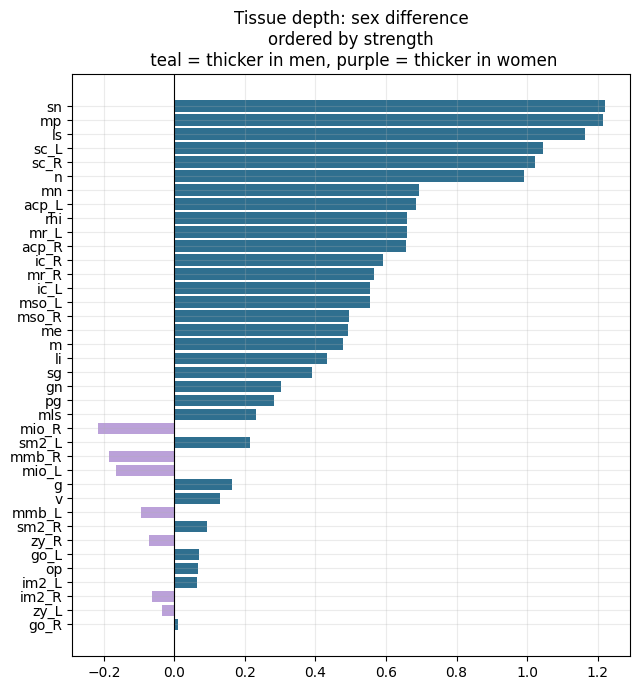

Landmarks thicker in WOMEN: {'mio_L': -0.17, 'mmb_L': -0.09, 'zy_L': -0.04, 'im2_R': -0.06, 'mio_R': -0.22, 'mmb_R': -0.19, 'zy_R': -0.07}
Largest effects (d): {'sn': 1.22, 'mp': 1.22, 'ls': 1.17, 'sc_L': 1.04, 'sc_R': 1.02}


In [40]:
# Sex differences in tissue depth
td["ancestry"] = td.id.str[:3]
sdf = pd.Series({c[3:]: sex_effect(td, c, sex_col="sex_td")
                 for c in TD_Cols if td[c].notna().mean() > 0.8})       # skip az_L / az_R (38% missing)
fig, ax = plt.subplots(figsize=(6.5, 7))
signed_barh(ax, sdf, "Tissue depth: sex difference\nordered by strength\n teal = thicker in men, purple = thicker in women")
plt.tight_layout(); plt.show()
print("Landmarks thicker in WOMEN:", {k: round(v, 2) for k, v in sdf[sdf < 0].items()})
print("Largest effects (d):", {k: round(v, 2) for k, v in sdf.reindex(sdf.abs().sort_values(ascending=False).index).head(5).items()})

**Takeaway:**

The **387 subjects** have **40 tissue-depth columns**.

Four columns have no definition in the reference sheet (`me`, `sg`, `az_L`, `az_R`), and `az_L/az_R` are also 38% empty, so we leave them out of the left-right and sex analyses.

Left and right are almost identical (median correlation 0.91), so L and R can be averaged to reduce noise.

Soft tissue is **clearly thicker in men around the mouth and nose**: subnasale (sn), mid-philtrum (mp), upper lip (ls) and the supra-canine points (sc) have d around 1 or above, *large* effects.

A few side landmarks (mid-infraorbital, mid-mandibular border, ...) are very slightly thicker in women (d down to about -0.2). The data contain **no age and no body weight (BMI)**, which strongly change tissue thickness: this limits how well any skull-to-face method can do.


6.  *Does the skull tell us anything beyond sex and ancestry :*

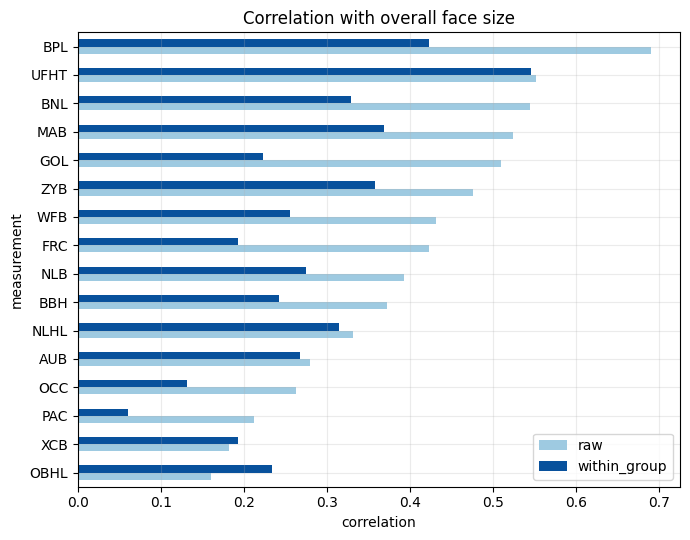

,raw,within_group,ci_lo,ci_hi
measurement,,,,
UFHT,0.55,0.55,0.46,0.63
BPL,0.69,0.42,0.32,0.52
MAB,0.52,0.37,0.26,0.47
ZYB,0.48,0.36,0.25,0.46
BNL,0.54,0.33,0.22,0.43
NLHL,0.33,0.31,0.20,0.42


In [41]:
group6 = trusted.sex + trusted.ancestry
face_size = np.exp(np.log(trusted[K_Cols]).mean(axis=1))        # one overall-size number per person

#Subtract the person's group mean
def residual(s):
    return s - s.groupby(group6).transform("mean")

#Approximate 95% CI of a correlation (Fisher z). We lose one degree of freedom per group mean removed.
def r_ci(r, n, n_groups=6):
    z, se = np.arctanh(r), 1 / np.sqrt(n - n_groups - 3)
    return np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)

rows = []
for c in Skull_Cols:
    raw = np.corrcoef(trusted[c], face_size)[0, 1]
    within = np.corrcoef(residual(trusted[c]), residual(face_size))[0, 1]
    lo, hi = r_ci(within, len(trusted))
    rows.append((c[2:], raw, within, lo, hi))
rel = pd.DataFrame(rows, columns=["measurement", "raw", "within_group", "ci_lo", "ci_hi"]).set_index("measurement")

ax = rel.sort_values("raw")[["raw", "within_group"]].plot.barh(figsize=(7, 5.5), color=["#9ecae1", "#08519c"])
ax.set_title("Correlation with overall face size"); ax.set_xlabel("correlation")
plt.tight_layout(); plt.show()
display(rel.sort_values("within_group", ascending=False).round(2).head(6))

**Takeaway:**

the raw correlations are large, but most of it comes from sex and ancestry.

What survives inside a group differs by type: the **face-skeleton** measurements (UFHT, BPL, MAB, ZYB, BNL) keep a clear correlation (about 0.33 to 0.55), whereas the **braincase** measurements (GOL, FRC, OCC, PAC) lose most of it. So the skull *does* carry information about face size beyond group membership.

Does it hold for face **shape**, not only size?


In [42]:
sex_ancestry = np.hstack([(trusted.sex == "M").astype(float).to_numpy().reshape(-1, 1),
                          pd.get_dummies(trusted.ancestry).astype(float).to_numpy()])      # sex + ancestry only
with_skull = np.hstack([trusted[Skull_Cols].astype(float).to_numpy(), sex_ancestry])       # skull + sex + ancestry
log_face = np.log(trusted[K_Cols].astype(float).to_numpy())

N_PC = 5
r2_group = np.zeros((5, N_PC))
r2_skull = np.zeros((5, N_PC))
for fold, (tr, te) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(with_skull)):
    pca_fold = PCA(N_PC).fit(log_face[tr])                       # fitted on training people only
    z_tr, z_te = pca_fold.transform(log_face[tr]), pca_fold.transform(log_face[te])
    for k in range(N_PC):
        for X, store in [(sex_ancestry, r2_group), (with_skull, r2_skull)]:
            model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(X[tr], z_tr[:, k])
            pred = model.predict(X[te])
            store[fold, k] = 1 - ((z_te[:, k] - pred) ** 2).sum() / ((z_te[:, k] - z_te[:, k].mean()) ** 2).sum()

preview = pd.DataFrame({"R2 sex+ancestry only": r2_group.mean(axis=0),
                        "R2 skull+sex+ancestry": r2_skull.mean(axis=0)}, index=[f"PC{k + 1}" for k in range(N_PC)])
preview["gain from the skull"] = preview.iloc[:, 1] - preview.iloc[:, 0]
display(preview.round(2))

,R2 sex+ancestry only,R2 skull+sex+ancestry,gain from the skull
PC1,0.54,0.74,0.21
PC2,0.16,0.14,-0.01
PC3,0.09,0.18,0.09
PC4,0.24,0.37,0.13
PC5,0.14,0.15,0.01


**Takeaway:**

The skull helps **a lot for overall face size** (PC1: R-squared rises from about 0.54 to 0.74) and noticeably for PC4 (about +0.13) and PC3 (about +0.09), but **not for PC2 and PC5** (changes near 0).

So the skull's information is mostly about **how big** the face is, and much less about its **proportions**.

This is consistent with the modest overall gain we expect over the group-average face, and it tells us what to look for in Step 2.

7.  *From distances to a 3D (data-integrity check)*

    The 66 distances are **all** pairwise distances between 12 landmarks. Like redrawing a road map from a table of distances between cities, we can recover each landmark's **3D position** (method: classical multidimensional scaling, MDS), then rotate the points so that left-right is x, up-down is y and front-back is z.

In [43]:
IDX = {landmark: i for i, landmark in enumerate(Landmarks)}          # landmark name -> row number

#One person's 66 distances .
def distance_matrix(row):
    D = np.zeros((12, 12))
    for c in K_Cols:
        a, b = c[2:].split("_")
        D[IDX[a], IDX[b]] = D[IDX[b], IDX[a]] = row[c]
    return D

def landmarks_3d(D):
    n = 12
    J = np.eye(n) - np.ones((n, n)) / n                    # centring matrix (puts the centre of the face at the origin)
    B = -0.5 * J @ (D ** 2) @ J                            # double centring: turns squared distances into inner products
    w, v = np.linalg.eigh(B)                               # eigen-decomposition (eigenvalues in ascending order)
    top = np.argsort(w)[::-1][:3]                          # keep the 3 largest = 3 spatial dimensions
    X = v[:, top] * np.sqrt(np.maximum(w[top], 0))
    # MDS does not know which way is up, left or front, so we fix the orientation with the landmark names:
    mean_of = lambda names: X[[IDX[n_] for n_ in names]].mean(axis=0)
    x_axis = mean_of(["exR", "acR", "chR"]) - mean_of(["exL", "acL", "chL"]); x_axis /= np.linalg.norm(x_axis)   # left -> right
    up = mean_of(["se"]) - mean_of(["sto"]); up -= (up @ x_axis) * x_axis; y_axis = up / np.linalg.norm(up)     # mouth -> nose bridge
    z_axis = np.cross(x_axis, y_axis)
    if (X[IDX["prn"]] - X.mean(axis=0)) @ z_axis < 0:      # the nose tip must point forward (removes the mirror ambiguity)
        z_axis = -z_axis
    return (X - X.mean(axis=0)) @ np.stack([x_axis, y_axis, z_axis], axis=1)

All 388 people: worst rebuilt-distance error = 0.0065 mm
Weight of the 4th and later dimensions relative to the 1st: at most 5.7e-05


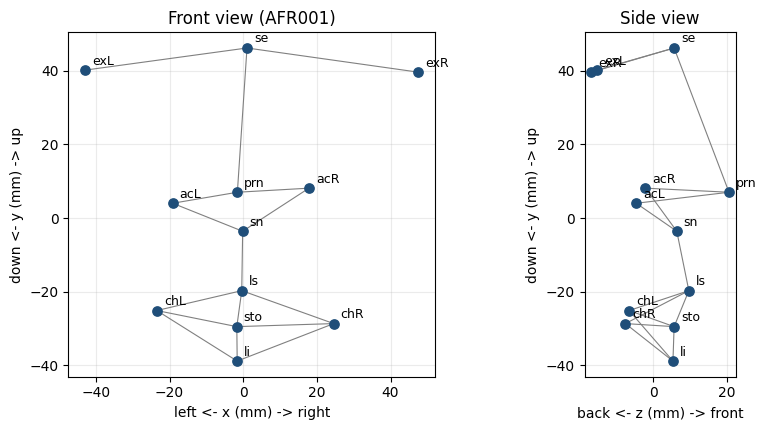

In [44]:
# Integrity check on ALL 388 people
worst, ratio = [], []
for _, row in fk.iterrows():
    D = distance_matrix(row)
    Q = landmarks_3d(D)
    D_back = np.linalg.norm(Q[:, None, :] - Q[None, :, :], axis=2)         # distances recomputed from the 3D points
    worst.append(np.abs(D - D_back).max())
    B = -0.5 * (np.eye(12) - 1 / 12) @ (D ** 2) @ (np.eye(12) - 1 / 12)
    eig = np.sort(np.linalg.eigvalsh(B))[::-1]
    ratio.append(np.abs(eig[3:]).max() / eig[0])                           # weight of everything beyond 3 dimensions
print(f"All {len(fk)} people: worst rebuilt-distance error = {max(worst):.4f} mm")
print(f"Weight of the 4th and later dimensions relative to the 1st: at most {max(ratio):.1e}")

row = trusted.iloc[0]
Q = landmarks_3d(distance_matrix(row))
links = [("exL", "se"), ("se", "exR"), ("se", "prn"), ("acL", "prn"), ("prn", "acR"), ("acL", "sn"), ("sn", "acR"), ("sn", "ls"),
         ("ls", "sto"), ("sto", "li"), ("chL", "sto"), ("sto", "chR"), ("chL", "ls"), ("ls", "chR"), ("chL", "li"), ("li", "chR")]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
for ax, (i, j, xlabel) in zip(axes, [(0, 1, "left <- x (mm) -> right"), (2, 1, "back <- z (mm) -> front")]):
    for a, b in links:                                                     # thin lines only to make the points readable as a face
        ax.plot([Q[IDX[a], i], Q[IDX[b], i]], [Q[IDX[a], j], Q[IDX[b], j]], color="grey", lw=0.8)
    ax.scatter(Q[:, i], Q[:, j], s=45, color="#1f4e79", zorder=3)
    for name, p in IDX.items():
        ax.annotate(name, (Q[p, i], Q[p, j]), textcoords="offset points", xytext=(5, 4), fontsize=9)
    ax.set_aspect("equal"); ax.set_xlabel(xlabel); ax.set_ylabel("down <- y (mm) -> up")
axes[0].set_title(f"Front view ({row['id']})"); axes[1].set_title("Side view")
plt.tight_layout(); plt.show()

**Takeaway:**

The error of about 0.006 mm (worst case over all 388 people) shows that the 66 distances are **exactly consistent with one coherent 3D shape** (the leftover dimensions are negligible: the data are recorded to 3 decimals).

 It is a **data-integrity check**: it tells us the distances come from real 3D points, which is why we can rebuild a face from predicted distances. It is **not** evidence that a skull-to-face *model* works: the coordinates were computed from these very distances.

### **Save Clean Dataset**

In [45]:
front = ["id", "ancestry", "sex", "use_for_training", "id_raw", "cranial_sheet"]
final = (data[front + Cranial_Cols + K_Cols + R_Cols + TD_Cols]
         .rename(columns={"id_raw": "id_cranial_original"})
         .sort_values("id").reset_index(drop=True))
final["note"] = np.where(final.id.isin(data.loc[data.hw_flag, "id"]),
                         "cranial ID scheme HWF/HWM, found in African sheets; sex mismatch in 2 of 12; id link by number is unverified -> excluded", "")

# Checks before saving: a saved file that fails these would corrupt Step 2.
assert len(final) == 282 and final.id.is_unique
assert int(final.use_for_training.sum()) == 270
assert final[K_Cols + R_Cols].notna().all().all(), "facial distances should have no missing values"
assert final.groupby("ancestry").size().to_dict() == {"AFR": 87, "ASN": 91, "EUR": 92, "HIS": 12}

final.to_csv("clean_dataset.csv", index=False)
print("Saved clean_dataset.csv:", final.shape[0], "rows x", final.shape[1], "columns")
print("Rows with use_for_training = True:", int(final.use_for_training.sum()))

Saved clean_dataset.csv: 282 rows x 196 columns
Rows with use_for_training = True: 270
